# 01. Нефтегаз: тренды цены Brent и обнаружение нефтяных разливов

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** Менеджмент в нефтегазе

**Бизнес-вопрос:** (А) Какие тренды и режимы волатильности видны в цене Brent и можно ли «угадать» направление цены? (Б) Можно ли автоматически отбирать радарные снимки с вероятным нефтяным пятном, чтобы аналитик проверял не все снимки, а только подозрительные?

**Данные:** (А) `brent-daily.csv` — ежедневная цена Brent, $/барр., 1987–2026 (EIA через [datasets/oil-prices](https://github.com/datasets/oil-prices), лицензия ODC-PDDL; снимок на 17.11.2026). (Б) `oil-spill.csv` — 937 фрагментов спутниковых радарных (SAR) снимков, 48 числовых признаков пятна и метка «нефть / не нефть» (Kubat et al., 1998; [зеркало](https://github.com/jbrownlee/Datasets)).

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

# Часть А. Цена Brent: разведка временного ряда

## Шаг 1. Вопрос и гипотеза
* Как менялись уровень и **волатильность** цены по годам? Где «кризисные режимы»?
* Гипотеза H0 (скептическая): по прошлым ценам направление цены через месяц предсказать нельзя лучше, чем «всегда расти».

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаг 2–3. Загрузка и паспорт данных

In [2]:
brent = pd.read_csv("https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/brent-daily.csv", parse_dates=["Date"])
print(brent.shape)
brent.info()
brent.describe().round(1)

(9132, 2)
<class 'pandas.DataFrame'>
RangeIndex: 9132 entries, 0 to 9131
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    9132 non-null   datetime64[us]
 1   Price   9132 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 142.8 KB


,Date,Price
count,9132,9132.0
mean,2007-12-11 02:31:32.247043,54.6
min,1987-05-20 00:00:00,9.1
25%,1998-02-08 06:00:00,20.6
50%,2008-10-28 12:00:00,52.8
75%,2017-11-10 18:00:00,77.6
max,2026-11-17 00:00:00,144.0
std,NaN,33.1


**Вывод:** ~9100 торговых дней, 2 столбца (дата, цена), пропусков нет. Пропущенные даты — выходные: это не ошибка, а свойство биржевых данных.

## Шаг 4–5. Подготовка и разведка: тренд и скользящее среднее

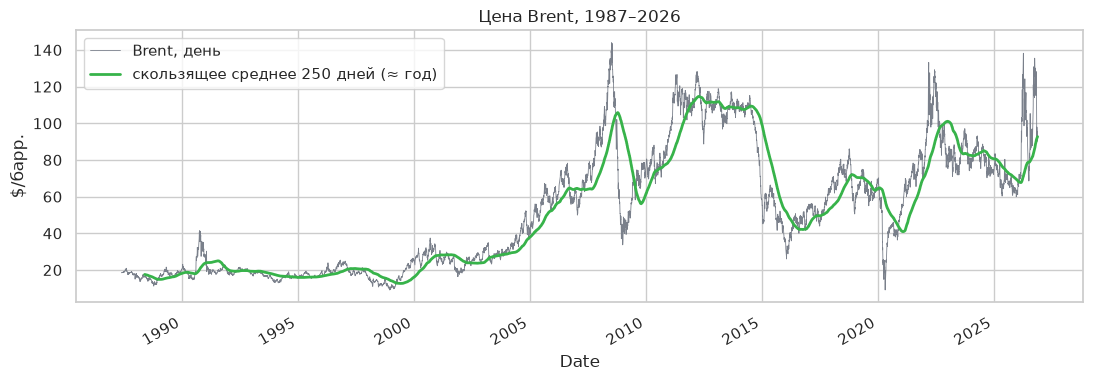

In [3]:
s = brent.set_index("Date")["Price"]
fig, ax = plt.subplots(figsize=(13, 4))
s.plot(ax=ax, lw=0.6, color="#7a808b", label="Brent, день")
s.rolling(250).mean().plot(ax=ax, lw=2, color="#37B34A", label="скользящее среднее 250 дней (≈ год)")
ax.set_ylabel("$/барр."); ax.legend(); ax.set_title("Цена Brent, 1987–2026")
plt.show()

In [4]:
yearly = pd.DataFrame({
    "средняя цена": s.resample("YE").mean(),
    "волатильность, % годовых": s.pct_change().groupby(s.index.year).std().values * np.sqrt(252) * 100,
})
yearly.index = yearly.index.year
yearly.round(1).tail(12)

,средняя цена,"волатильность, % годовых"
Date,,
2015,52.3,40.6
2016,43.6,46.3
2017,54.1,25.9
2018,71.3,29.4
2019,64.3,33.3
2020,42.0,110.0
2021,70.9,33.6
2022,100.9,47.0
2023,82.5,33.9


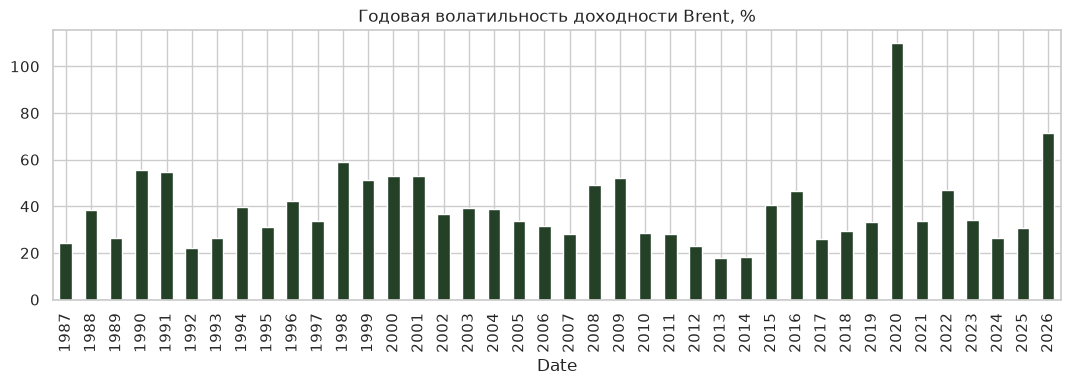

In [5]:
ax = yearly["волатильность, % годовых"].plot.bar(figsize=(13, 3.5), color="#244128")
ax.set_title("Годовая волатильность доходности Brent, %"); plt.show()

**Вывод по шагам 4–5:** длинный тренд прерывается шоками (2008, 2014–2016, 2020, 2022). В 2026 г. волатильность — максимальная с 2020 г. (≈ 71% годовых против 27–34% в 2023–2025): цена выросла с ~61 $ в январе до ~138 $ в апреле. Для бизнеса это аргумент за хеджирование и сценарное планирование бюджета.

## Шаги 6–10. Можно ли предсказать направление цены через 4 недели?

Признаки: изменение за 1 и 4 недели, отклонение от 12-недельного среднего. Цель: **1 — цена через 4 недели выше**. Для временных рядов делим выборку **по времени** (прошлое → обучение, будущее → тест), а не случайно!

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

w = s.resample("W").last()
d = pd.DataFrame({"chg_1w": w.pct_change(), "chg_4w": w.pct_change(4), "vs_ma12": w / w.rolling(12).mean() - 1})
d["target_up"] = (w.shift(-4) > w).astype(int)
d = d.dropna().iloc[:-4]          # последние 4 недели без «ответа» отбрасываем
cut = int(len(d) * 0.75)          # разбиение по времени
train, test = d.iloc[:cut], d.iloc[cut:]
X_cols = ["chg_1w", "chg_4w", "vs_ma12"]
m = LogisticRegression().fit(train[X_cols], train["target_up"])
acc_model = accuracy_score(test["target_up"], m.predict(test[X_cols]))
acc_base = max(test["target_up"].mean(), 1 - test["target_up"].mean())
print(f"Тест с {test.index[0].date()} по {test.index[-1].date()}")
print(f"Базовая линия («всегда вверх»): {acc_base:.3f}   Логистическая регрессия: {acc_model:.3f}")

Тест с 2017-06-04 по 2026-10-25
Базовая линия («всегда вверх»): 0.554   Логистическая регрессия: 0.556


**Вывод:** точность модели ≈ 56% и практически равна базовой линии ≈ 55% — **модель не лучше монетки**. Это тоже научный результат: рынок нефти «слабо эффективен», и прошлые цены сами по себе не дают преимущества. Менеджеру полезнее моделировать *риски* (волатильность, сценарии), а не «угадывать» цену. Честно показанный отрицательный результат ценнее красивой, но ложной точности.

# Часть Б. Классификация: нефтяное пятно на радарном снимке

## Шаг 1. Вопрос
Спутник (SAR) видит тёмные пятна на воде; лишь часть из них — нефть (остальное — штиль, водоросли, «двойники»). **Пропустить разлив (FN) намного дороже**, чем проверить ложную тревогу (FP) → главная метрика — **recall** класса «нефть».

## Шаги 2–4. Загрузка, паспорт, подготовка

In [7]:
spill = pd.read_csv("https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/oil-spill.csv", header=None)
spill.columns = ["patch"] + [f"f{i}" for i in range(1, 49)] + ["oil"]
print(spill.shape)
print("Пропусков:", spill.isna().sum().sum())
spill["oil"].value_counts()

(937, 50)
Пропусков: 0


oil
0    896
1     41
Name: count, dtype: int64

**Вывод:** 937 пятен, лишь **41 (4,4%)** — нефть. Сильный **дисбаланс классов**: модель «всегда не нефть» получит 95,6% accuracy и не найдёт ни одного разлива. Столбец `patch` — номер снимка (идентификатор), в модель его не берём.

## Шаги 5–6. Разведка: чем нефтяные пятна отличаются?

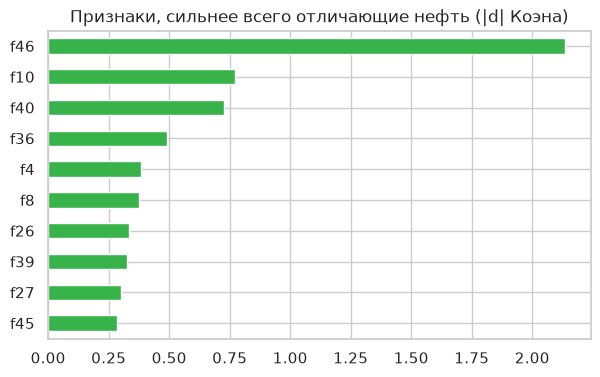

In [8]:
X = spill.drop(columns=["patch", "oil"]); y = spill["oil"]
# стандартизованная разница средних (нефть vs не нефть): какие признаки разделяют классы
eff = ((X[y == 1].mean() - X[y == 0].mean()) / X.std()).abs().sort_values(ascending=False)
eff.head(10).plot.barh(figsize=(7, 4), color="#37B34A"); plt.gca().invert_yaxis()
plt.title("Признаки, сильнее всего отличающие нефть (|d| Коэна)"); plt.show()

**Вывод:** несколько признаков (форма, контраст, площадь пятна) заметно отличают нефть → задача имеет смысл для ML.

## Шаги 7–10. Модель, базовая линия, учёт дисбаланса

In [9]:
def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
quality(y_te, base.predict(X_te), name="Базовая линия")

m1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X_tr, y_tr)
quality(y_te, m1.predict(X_te), m1.predict_proba(X_te)[:, 1], name="Лог. регрессия")

m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")).fit(X_tr, y_tr)
quality(y_te, m2.predict(X_te), m2.predict_proba(X_te)[:, 1], name="Лог. регрессия + веса классов")

Базовая линия                accuracy=0.957  precision=0.000  recall=0.000  f1=0.000
Лог. регрессия               accuracy=0.962  precision=0.571  recall=0.400  f1=0.471  ROC-AUC=0.946


Лог. регрессия + веса классов accuracy=0.894  precision=0.273  recall=0.900  f1=0.419  ROC-AUC=0.957

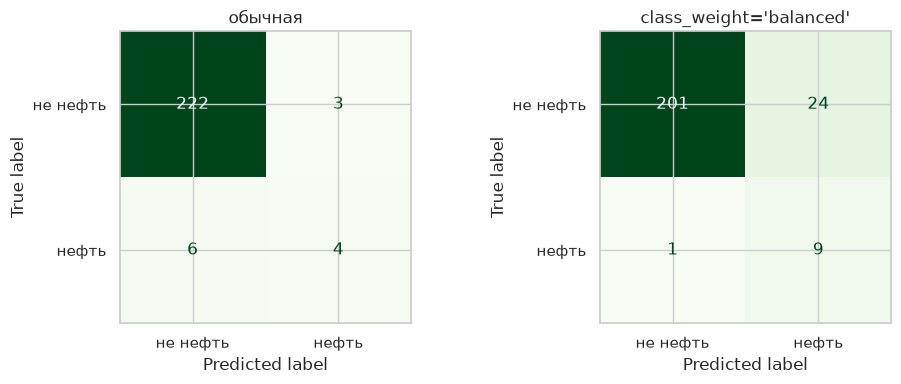

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (mdl, t) in zip(ax, [(m1, "обычная"), (m2, "class_weight='balanced'")]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, mdl.predict(X_te)), display_labels=["не нефть", "нефть"]).plot(ax=a, cmap="Greens", colorbar=False)
    a.set_title(t)
plt.tight_layout(); plt.show()

## Итоговые выводы для бизнеса

1. **Brent:** данные полезны для оценки *рисков* (волатильность 2026 г. ≈ 71% годовых — в 2+ раза выше 2023–2025), но не для «угадывания» цены: модель ≈ базовая линия.
2. **Разливы:** обычная модель по accuracy (96%) почти не отличается от «всегда нет», а находит лишь 4 из 10 разливов в тесте. **Взвешивание классов** поднимает recall до **0,9 (9 из 10)** ценой 24 ложных тревог из 235 снимков — аналитик смотрит ~14% снимков вместо 100%.
3. **Управленческий эффект:** сокращение ручного просмотра в ~7 раз при сохранении 90% обнаружения; порог тревоги — решение менеджера (цена пропуска vs цена проверки).

**Ограничения:** малая выборка разливов (41), признаки обезличены; перед внедрением — проверка на снимках своего региона.